# E3 — TabPFN 2.5: inferencia local y evaluación comparable

Basado en el [informe técnico TabPFN‑2.5, versión 2](https://arxiv.org/abs/2511.08667v2)
y el [checkpoint oficial de Prior Labs](https://huggingface.co/Prior-Labs/tabpfn_2_5).
Esta aproximación usa la librería Python oficial, como excepción al criterio de implementación
propia de la búsqueda anterior. No se reimplementa ni se preentrena la red fundacional.

Los resultados quedan en `resultados/e3/tabpfn_25/`. Se ejecuta en el equipo local:
los datos de estudiantes no se envían a un servicio de inferencia.

## Instalación y checkpoint exacto

Usar el entorno compartido. Desde la raíz del proyecto:
```powershell
Precalculo\venv\Scripts\python.exe -m pip install torch==2.9.1 --index-url https://download.pytorch.org/whl/cpu
Precalculo\venv\Scripts\python.exe -m pip install -r Precalculo/requirements_tabpfn25.txt
Precalculo\venv\Scripts\python.exe Precalculo/descargar_tabpfn25.py
```
Se fija el SDK `tabpfn==6.4.1` y se carga mediante ruta explícita
`tabpfn-v2.5-regressor-v2.5_default.ckpt`, con revisión y SHA‑256 registrados.
La versión del paquete **no** es la versión del modelo. No se permite reemplazar
silenciosamente los pesos por TabPFN 2 o por otra generación.

El checkpoint está preentrenado con datos sintéticos por sus autores; eso no aumenta ni altera
los registros de este proyecto. Su licencia permite investigación y evaluación interna y restringe
usos comerciales/productivos: [licencia de los pesos](https://huggingface.co/Prior-Labs/tabpfn_2_5/blob/main/LICENSE).
Los pesos se guardan localmente, fuera de Git; no se instalan componentes CUDA.

In [1]:
from pathlib import Path
import os
import sys
book = Path.cwd() if (Path.cwd() / 'entregable3.py').exists() else Path.cwd() / 'Precalculo'
sys.path.insert(0, str(book.resolve()))
from evaluacion_nuevos_e3 import prepare_tabpfn_environment
prepare_tabpfn_environment()  # Desactivar telemetría ANTES de importar tabpfn.
import torch
import tabpfn
import importlib.metadata
print('SDK:', importlib.metadata.version('tabpfn'), '| PyTorch:', torch.__version__)
print('Dispositivo de este experimento: CPU. No se necesita token para el checkpoint público.')

SDK: 6.4.1 | PyTorch: 2.9.1+cpu
Dispositivo de este experimento: CPU. No se necesita token para el checkpoint público.


## Datos, variables y protocolo del tablero

Se importa la preparación canónica de `entregable3.py`, sin regenerar ni aumentar datos.
Se aplica el mismo filtro de objetivo faltante y reglas de negocio, conservando outliers válidos.
La respuesta es **nota_primer_parcial**. Son los mismos **8 predictores numéricos y 7 categóricos**.
`nota_final`, estudiante, periodo y fila fuente nunca se usan como predictores.

**Partición temporal:** train contiene los periodos anteriores a 202530 (1309 registros,
1293 estudiantes); test reserva 202530 (188 registros, 188 estudiantes). Se purgan de train
los estudiantes presentes en el periodo reservado, incluso si su objetivo de test falta.

**CV externa:** exactamente las mismas asignaciones de GroupKFold de cinco folds del tablero.
Los 1293 IDs son grupos indivisibles que se distribuyen entre cinco folds: cada fila recibe
una predicción OOF de un modelo que no vio ninguna fila de ese estudiante. Los folds no son
periodos: el periodo futuro constituye una evaluación separada. No se usa test para elegir parámetros.

**Preparación común al SVM/Ridge/Lasso/KNN:** mediana numérica, `log1p` en los tres tiempos,
StandardScaler, moda categórica y OneHotEncoder con referencia, ignorando categorías nuevas.
Cada preparación se ajusta únicamente en su subconjunto de fit, dentro del pipeline.
Las aserciones siguientes comprueban valores, orden de filas, hashes y folds contra los resultados del tablero.

In [2]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display

BOOK = Path.cwd()
if not (BOOK / 'entregable3.py').exists():
    BOOK = BOOK / 'Precalculo'
if not (BOOK / 'entregable3.py').exists():
    raise RuntimeError('Abre el notebook desde Precalculo o la raíz del proyecto.')
sys.path.insert(0, str(BOOK.resolve()))
from entregable3 import FEATURES, NUMERIC, CATEGORICAL, TARGET, GROUP, PERIOD, metrics
from evaluacion_nuevos_e3 import partitions, run_experiment, display_results

train, test, folds, audit = partitions()
display(pd.DataFrame([audit]))
display(pd.DataFrame({'variable': FEATURES, 'tipo': ['numérica']*8 + ['categórica']*7}))
display(pd.DataFrame([{'fold': k, 'fit_filas': len(fi), 'validacion_filas': len(va),
                      'fit_estudiantes': train.iloc[fi][GROUP].nunique(),
                      'validacion_estudiantes': train.iloc[va][GROUP].nunique(),
                      'estudiantes_compartidos': len(set(train.iloc[fi][GROUP]) & set(train.iloc[va][GROUP]))}
                     for k, (fi, va) in enumerate(folds, 1)]))
assert len(train) == 1309 and len(test) == 188
assert not set(train[GROUP]) & set(test[GROUP])
assert train[PERIOD].max() < test[PERIOD].min()
print('Integridad confirmada: fuente, 15 variables, filas, periodo y folds iguales al tablero.')

,source_rows,source_students,missing_target,test_period,train_periods,purged_overlap_rows,purged_overlap_students,train_raw,test_raw,excluded_train,excluded_test,rules_train,rules_test,train_valid,test_valid,train_students,test_students,shared_students,outliers_removed
0,1527,1506,30,202530,"[202310, 202330, 202410, 202430, 202510]",0,0,1309,188,0,0,"{'dominio': 0, 'tiempo_cero': 0, 'aprendidos_c...","{'dominio': 0, 'tiempo_cero': 0, 'aprendidos_c...",1309,188,1293,188,0,0


,variable,tipo
0,Icfes_nuevo,numérica
1,Icfes_Matematicas,numérica
2,Tiempo_empleado_en_la_verificación_de_conocimi...,numérica
3,Dominio_Inicial,numérica
4,avance_precalculo_aleks,numérica
5,Dominio_Final,numérica
6,Tiempo_Total_Tiempo,numérica
7,Tiempo_total_Aprendidos_hora,numérica
8,Categoria_temas_inicial,categórica
9,Categoria_temas_final,categórica


,fold,fit_filas,validacion_filas,fit_estudiantes,validacion_estudiantes,estudiantes_compartidos
0,1,1047,262,1035,258,0
1,2,1047,262,1034,259,0
2,3,1047,262,1034,259,0
3,4,1047,262,1034,259,0
4,5,1048,261,1035,258,0


Integridad confirmada: fuente, 15 variables, filas, periodo y folds iguales al tablero.


## Cómo se adapta TabPFN al protocolo

TabPFN realiza predicción **en contexto**: `fit` registra el conjunto de entrenamiento y
prepara la inferencia con pesos ya preentrenados; no corresponde a entrenar una red desde cero.
Solo los datos del fit externo constituyen el contexto para predecir ese fold.

Se reutiliza exactamente el preprocesamiento externo del SVM, aprendido dentro de cada fit.
TabPFN podría trabajar con una representación categórica diferente; aquí se elige la misma
matriz imputada/escalada/one-hot para controlar la comparación solicitada. Esto **no reproduce
la configuración óptima ni los benchmarks del artículo**. Las transformaciones internas del
ensamble de TabPFN siguen siendo parte del modelo. Las métricas se calculan sobre su predicción
media en la escala de la nota, usando la función común.

Se fijan de antemano cuatro estimadores del ensamble (el SDK ofrece ocho por defecto), CPU,
semilla 42, `low_memory`, `memory_saving_mode=True` y un trabajo de preparación. Se conservan
todas las filas de cada fit; no se submuestrean estudiantes para ahorrar recursos. Se desactivan
telemetría y aperturas automáticas de navegador.

**No se realiza búsqueda de hiperparámetros**: por ello no hay selección interna ni necesidad
de CV interna. Se usan los mismos cinco folds externos que el resto y un ajuste final en todo
train. Si posteriormente se ajusta el número de estimadores u otro parámetro, deberá hacerse
con CV interna por estudiante, conservando el test temporal reservado.

In [3]:
from evaluacion_nuevos_e3 import tabpfn_pipeline, MODEL_DIR
pipeline = tabpfn_pipeline()
display(pipeline)
manifest = json.loads((MODEL_DIR / 'procedencia.json').read_text(encoding='utf-8'))
display(pd.DataFrame([manifest]))
assert 'v2.5-regressor-v2.5_default' in str(pipeline.named_steps['modelo'].model_path)
print('Checkpoint verificado por SHA-256; inferencia exclusivamente local.')

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_log', ...), ('num_plain', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: floa

,repository,revision,filename,url,sha256,bytes,license_url
0,Prior-Labs/tabpfn_2_5,6c45f3a6d0d07c6c5f62572e04a0c2929de91b8b,tabpfn-v2.5-regressor-v2.5_default.ckpt,https://huggingface.co/Prior-Labs/tabpfn_2_5/r...,6e0308b7e5f3a8325b798b96d986b2b282c3608b1cda6e...,40831995,https://huggingface.co/Prior-Labs/tabpfn_2_5/b...


Checkpoint verificado por SHA-256; inferencia exclusivamente local.


## Evaluación de cinco folds y test temporal

La ejecución completa puede ser lenta en CPU. No se reducen las filas ni se sustituye
el modelo si faltan memoria o pesos: la ejecución informa el error y no inventa métricas.
La caché se usa únicamente cuando el reporte completo coincide con los hashes actuales.

In [4]:
report = run_experiment('tabpfn_25', force=False)
display(pd.DataFrame(report['fold_audit']))
print('Configuración fijada:', report['best_params'])

tabpfn_25: resultados completos verificados; force=True para recalcular.


,fold,fit_rows,validation_rows,shared_students,best_params,seconds
0,1,1047,262,0,"{'n_estimators': 4, 'device': 'cpu', 'model_pa...",98.503129
1,2,1047,262,0,"{'n_estimators': 4, 'device': 'cpu', 'model_pa...",81.787818
2,3,1047,262,0,"{'n_estimators': 4, 'device': 'cpu', 'model_pa...",76.288507
3,4,1047,262,0,"{'n_estimators': 4, 'device': 'cpu', 'model_pa...",77.381895
4,5,1048,261,0,"{'n_estimators': 4, 'device': 'cpu', 'model_pa...",53.569150


Configuración fijada: {'n_estimators': 4, 'device': 'cpu', 'model_path': 'tabpfn-v2.5-regressor-v2.5_default.ckpt', 'fit_mode': 'low_memory', 'random_state': 42}


## Métricas e interpretación

Se llama directamente a `entregable3.metrics`: **RMSE**, **MAE**, **MAPE (%)** y **R²**,
en la escala original de la nota, sin recortar las predicciones. Menor error es mejor;
mayor R² es mejor. MAPE conserva la definición del tablero y es sensible a notas cercanas a cero.

Se reportan los cinco resultados externos, su media y desviación estándar poblacional (`ddof=0`),
y las métricas sobre todas las predicciones OOF reunidas (no necesariamente iguales a la media por fold).
El test temporal se presenta por separado. Los IC del 95% se obtienen con 1000 réplicas bootstrap
por estudiante, semilla 42; la diferencia frente al SVM usa las mismas muestras en cada réplica.
Un intervalo de diferencia que incluye cero no respalda una mejora concluyente. Estos intervalos
son condicionales al modelo ajustado y no incluyen la variabilidad de volver a entrenarlo.

La comparación con los modelos existentes es descriptiva: el test del tablero ya fue inspeccionado
en fases anteriores. No equivale a una nueva prueba ciega. No se promete superar los modelos previos.

,metrica,media_cv,sd_cv,OOF_agrupado
0,RMSE,0.80712,0.04409,0.80831
1,MAE,0.63134,0.03925,0.63133
2,MAPE (%),23.54342,2.24384,23.54276
3,R²,0.47493,0.05742,0.47690


,metrica,estimacion,IC_2.5%,IC_97.5%
0,RMSE,0.89828,0.81202,0.98835
1,MAE,0.71549,0.63831,0.79520
2,MAPE (%),27.76105,22.41186,34.06545
3,R²,0.46422,0.35967,0.54943


,Modelo,RMSE,MAE,MAPE (%),R²
0,SVM lineal,0.92771,0.75544,29.66456,0.42854
1,Dummy media,1.25606,1.10447,42.31451,-0.04757
2,KNN,0.92327,0.75403,29.58450,0.43399
3,Ridge,0.91709,0.75451,29.57214,0.44155
4,Lasso,0.91965,0.75304,29.55197,0.43842
5,Random Forest,0.93964,0.76585,29.73202,0.41375
6,XGBoost,0.90627,0.72892,28.40477,0.45464
7,"TabPFN 2.5 (4 estimadores, CPU)",0.89828,0.71549,27.76105,0.46422


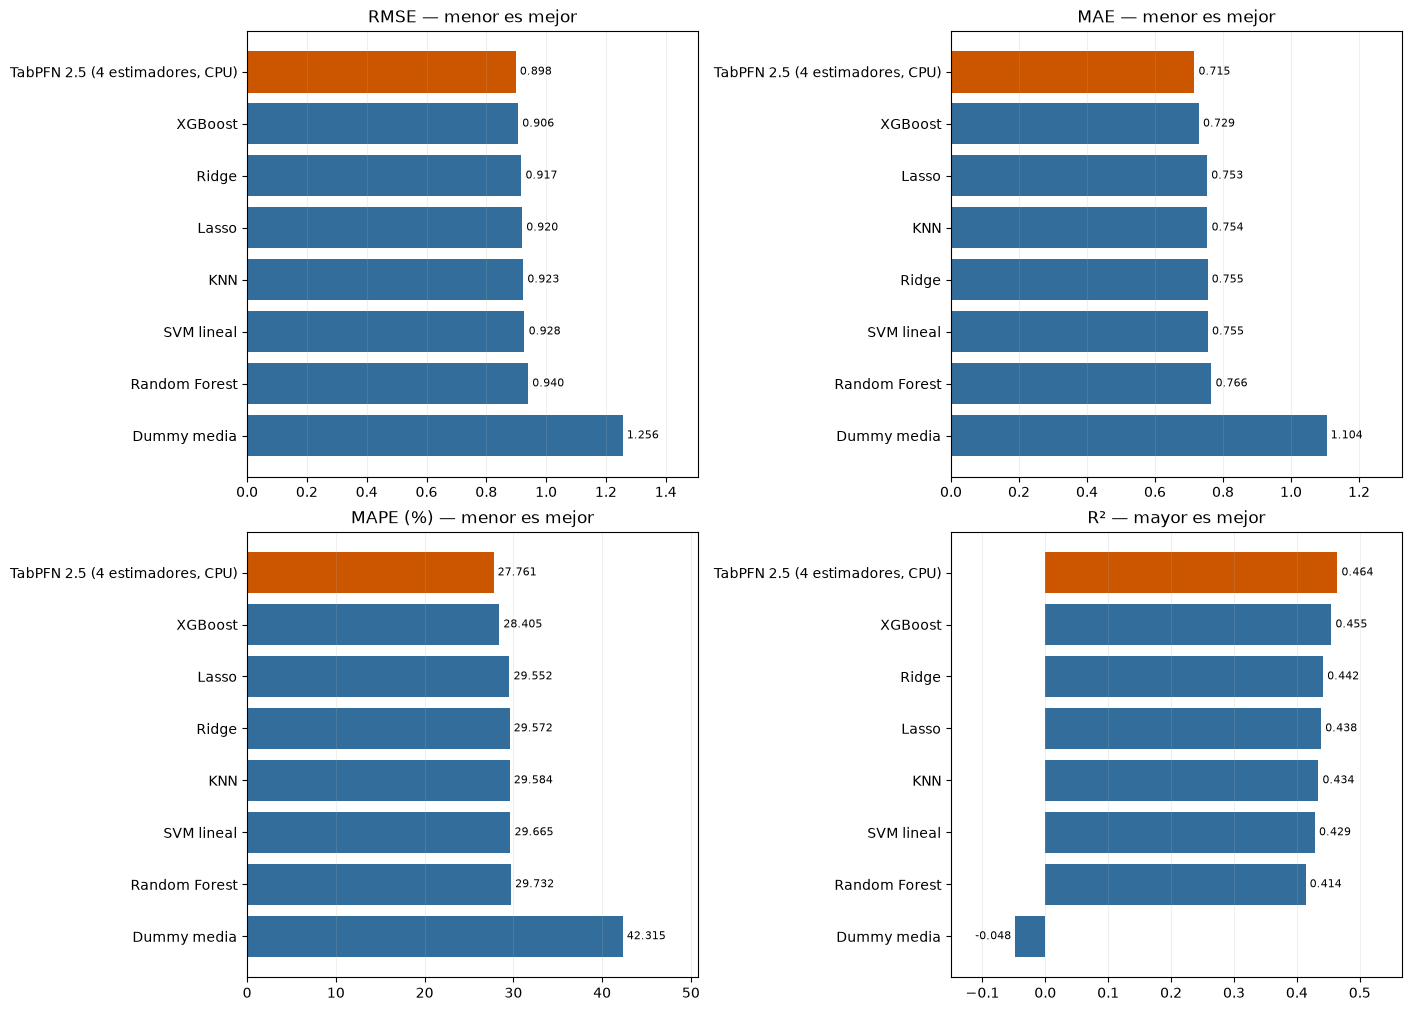

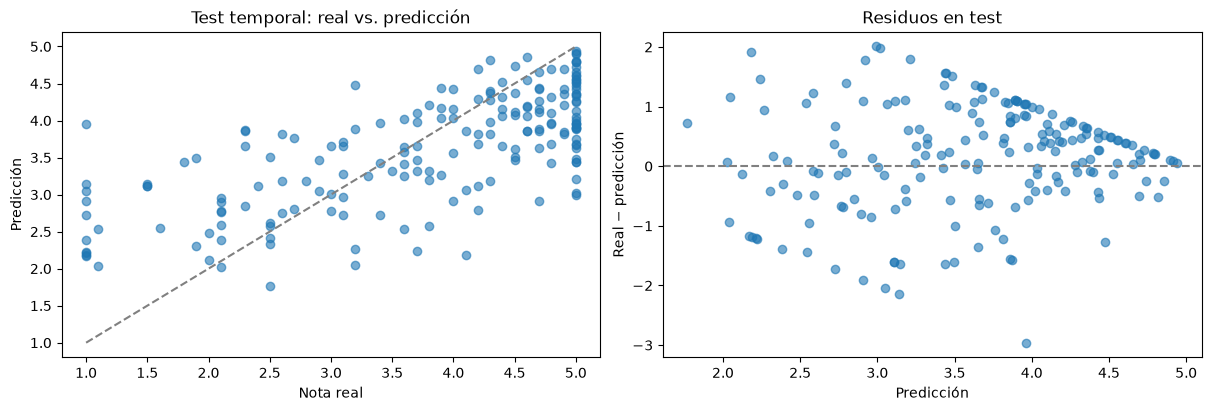

,metrica,nuevo_menos_SVM,IC_2.5%,IC_97.5%
0,RMSE,-0.02943,-0.06275,0.00316
1,MAE,-0.03995,-0.07165,-0.00688
2,MAPE (%),-1.90351,-3.06736,-0.78923
3,R²,0.03568,-0.00370,0.07435


In [5]:
display_results(report)
display(pd.DataFrame(report['paired_vs_svm']).round(5))

## Reproducibilidad y límites

Se guardan las versiones, revisión de pesos, SHA‑256, auditoría de particiones,
predicciones OOF/test sin identificadores y métricas comparables al tablero. No se serializa
el objeto TabPFN ajustado, porque su contexto contiene ejemplos de entrenamiento; para
reproducir predicciones se carga el checkpoint y se ejecuta este protocolo sobre los datos locales.

Los resultados con cuatro estimadores, CPU y preparación común son propios de este experimento.
La superioridad en otros datasets publicada por los autores no garantiza una mejora aquí.
Las diferencias frente a XGBoost, Ridge y SVM se interpretan con CV y con los intervalos,
sin seleccionar configuraciones mirando test.

In [6]:
print(json.dumps(report['versions'], indent=2, ensure_ascii=False))
print('Resultados:', (BOOK / 'resultados/e3/tabpfn_25').resolve())

{
  "numpy": "2.3.5",
  "pandas": "3.0.1",
  "scikit-learn": "1.9.1",
  "scipy": "1.18.1",
  "tabpfn": "6.4.1",
  "torch": "2.9.1+cpu"
}
Resultados: C:\Users\Rubiel\Documents\Machine Learning Maestria\Precalculo\resultados\e3\tabpfn_25


## Pesos preentrenados y significancia frente al SVM

Los pesos oficiales de TabPFN 2.5 se mantienen fijos: **no se entrenaron desde cero
ni se hizo fine-tuning con estos estudiantes**. `fit(X_train, y_train)` aprende la preparación
y establece los ejemplos etiquetados como contexto para la inferencia. Por tanto, sí utiliza
las notas de train para predecir; no funciona únicamente con los pesos y una fila aislada.
En cada fold, el contexto excluye todos los estudiantes de validación. En el ajuste final,
el contexto son las 1309 filas de train y se predicen las 188 filas del periodo 202530.
Los cuatro estimadores son variantes de inferencia del ensamble, no cuatro redes reentrenadas.
Ver el [artículo](https://arxiv.org/html/2511.08667v2) y `tabpfn_pipeline()`.

Se realiza una **prueba bilateral de permutación pareada**, con 99999 permutaciones,
semilla 42 y alpha .05, sobre las predicciones ya obtenidas. Se intercambian las etiquetas
de modelo dentro de cada estudiante, manteniendo juntos todos sus registros; aquí son
188 estudiantes con una fila cada uno. H0 supone intercambiabilidad de las pérdidas
cuadradas pareadas. El estadístico es SSE_TabPFN − SSE_SVM. También se calculan IC95%
percentiles con 10000 réplicas bootstrap pareadas por estudiante.

Para el mismo test, `RMSE = sqrt(SSE/n)` y `R² = 1 − SSE/SST`, con SST común a ambos.
Durante las permutaciones la suma SSE_TabPFN + SSE_SVM se conserva. Las diferencias de RMSE
y R² son transformaciones monótonas (de signo opuesto) de la diferencia SSE; por eso este
contraste produce el mismo p-valor para las dos métricas. **No son dos evidencias independientes**.
No se aplica un t-test a los cinco folds, cuyos modelos comparten datos de entrenamiento.
Referencia: [permutación pareada en SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html).


In [7]:
from significancia_tabpfn_svm import compare
significance = compare()
display(pd.DataFrame(significance['rows']).round(6))
print('Permutaciones:', significance['n_permutations'])
print('Bootstrap:', significance['n_bootstrap'])
print('Conclusión al 5%:', 'diferencia significativa' if significance['rows'][0]['rechaza_H0']
      else 'no se rechaza H0; evidencia insuficiente para declarar una diferencia')
print(significance['scope'])

,metrica,TabPFN,SVM,TabPFN_menos_SVM,IC_2.5%,IC_97.5%,p_bilateral,alpha,rechaza_H0
0,RMSE,0.898277,0.927706,-0.029428,-0.061618,0.002094,0.06888,0.05,False
1,R²,0.464223,0.428543,0.035680,-0.002669,0.074404,0.06888,0.05,False


Permutaciones: 99999
Bootstrap: 10000
Conclusión al 5%: no se rechaza H0; evidencia insuficiente para declarar una diferencia
Inferencia exploratoria condicional a estos dos modelos y al periodo 202530. Supone estudiantes independientes e intercambiabilidad pareada bajo H0; no incorpora variabilidad de reentrenamiento ni garantiza otros periodos. El test ya fue inspeccionado previamente. No rechazar H0 no prueba equivalencia.


La diferencia puntual favorece a TabPFN,
pero **p = 0.06888 > 0.05** y ambos intervalos incluyen cero. No se demuestra una mejora
estadísticamente significativa en RMSE o R², ni se demuestra que los modelos sean equivalentes.
El contraste es exploratorio, condicional a los modelos ajustados y a este periodo; no incluye
variabilidad por reentrenamiento. Los IC de esta sección usan 10000 réplicas, frente a las
1000 de la sección previa; las pequeñas diferencias numéricas no cambian la conclusión.